# EDA

In [1]:
%load_ext watermark
%watermark

Last updated: 2022-10-08T17:17:53.749921-05:00

Python implementation: CPython
Python version       : 3.7.4
IPython version      : 7.8.0

Compiler    : MSC v.1915 64 bit (AMD64)
OS          : Windows
Release     : 10
Machine     : AMD64
Processor   : Intel64 Family 6 Model 158 Stepping 9, GenuineIntel
CPU cores   : 8
Architecture: 64bit



# Objetivos:

- Analizar e investigar conjuntos de datos y resumir sus principales características
- Análisis Bivariado
- Análisis Multivariado
- Encontrar correlaciones

In [2]:
import pandas as pd
%matplotlib inline 
# no crea widget ni nada para no presentar resultados.
import pandas as pd
import numpy as np
#import matplotlib.pyplot as plt
import matplotlib as plt
import seaborn as sns
from matplotlib.pyplot import figure
import warnings
warnings.filterwarnings("ignore")


plt.rcParams['figure.figsize'] = (10,10) # 10 pulgadas de ancho y 10 de alto para todos los plots


In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The text.latex.preview rcparam was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The mathtext.fallback_to_cm rcparam was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: Support for setting the 'mathtext.fallback_to_cm' rcParam is deprecated since 3.3 and will be removed two minor releases later; use 'mathtext.fallback : 'cm' instead.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The validate_bool_maybe_none function was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\

In [3]:
bank_dp = pd.read_parquet("../output/data-bank_2_FE.parquet",engine='pyarrow')

In [4]:
bank_dp.head(5)

,edad,trabajo,estadoCivil,educacion,flag_mora,prom_saldoAnual,flag_hipotecario,flag_prestamo,tipo_contacto,dia_UltContacto,mes_UltContacto,seg_UltContacto,cant_contactoCampanha,cant_contactoBeforeCampanha,result_campanha,FlagTarget_DP,Rango_edad
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,0,unknown,yes,55-60
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,0,unknown,yes,55-60
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,0,unknown,yes,41-45
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,0,unknown,yes,51-55
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,0,unknown,yes,51-55


In [5]:
bank_dp.shape

(11152, 17)

In [6]:
round(bank_dp.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
edad,11152.0,41.23,11.92,18.0,32.0,39.0,49.00,95.0
prom_saldoAnual,11152.0,1528.36,3225.79,-6847.0,122.0,550.0,1708.25,81204.0
dia_UltContacto,11152.0,15.66,8.42,1.0,8.0,15.0,22.00,31.0
seg_UltContacto,11152.0,372.16,347.19,2.0,138.0,255.0,496.00,3881.0
cant_contactoCampanha,11152.0,2.49,2.56,1.0,1.0,2.0,3.00,32.0
cant_contactoBeforeCampanha,11152.0,0.81,2.07,0.0,0.0,0.0,1.00,30.0


## Relación entre características categóricas y target

In [7]:
categorical_features=[feature for feature in bank_dp.columns if ((bank_dp[feature].dtypes=='O') & (feature not in ['FlagTarget_DP']))]

In [8]:
for feature in categorical_features:
    print('The feature is `{}` and number of categories are {}'.format(feature,len(bank_dp[feature].unique())))

The feature is `trabajo` and number of categories are 12
The feature is `estadoCivil` and number of categories are 3
The feature is `educacion` and number of categories are 4
The feature is `flag_mora` and number of categories are 2
The feature is `flag_hipotecario` and number of categories are 2
The feature is `flag_prestamo` and number of categories are 2
The feature is `tipo_contacto` and number of categories are 3
The feature is `mes_UltContacto` and number of categories are 12
The feature is `result_campanha` and number of categories are 4
The feature is `Rango_edad` and number of categories are 13


### Columna: _FlagTarget_DP_

En el diagrama, vemos que los recuentos de "yes" y "no" para los valores de "depósito" están cerca, por lo que podemos usar la precisión como métrica para un modelo que predice el resultado de la campaña

<AxesSubplot:title={'center':'Deposit value counts'}>

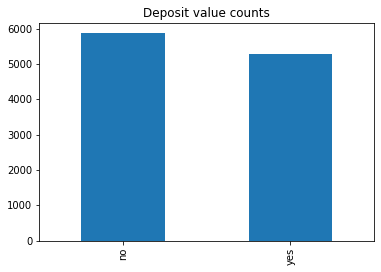

In [9]:
value_counts = bank_dp['FlagTarget_DP'].value_counts()

value_counts.plot.bar(title = 'Deposit value counts')

In [10]:
#job and deposit
def fx_ColumnvsTarget(df,name_column,name_title):
    j_df = pd.DataFrame()

    j_df['yes'] = df[df['FlagTarget_DP'] == 'yes'][name_column].value_counts()
    j_df['no'] = df[df['FlagTarget_DP'] == 'no'][name_column].value_counts()
    j_df.plot.bar(title = name_title)

### Columna: _trabajo_

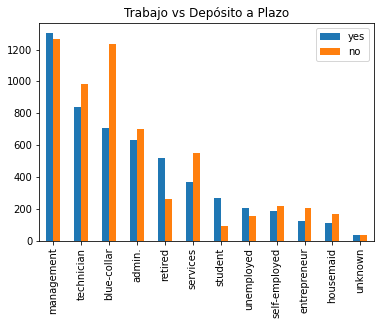

In [11]:
fx_ColumnvsTarget(bank_dp,"trabajo","Trabajo vs Depósito a Plazo")

### Columna: _estadoCivil_

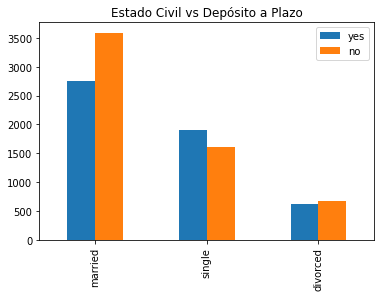

In [12]:
fx_ColumnvsTarget(bank_dp,"estadoCivil","Estado Civil vs Depósito a Plazo")

### Columna: _educacion_

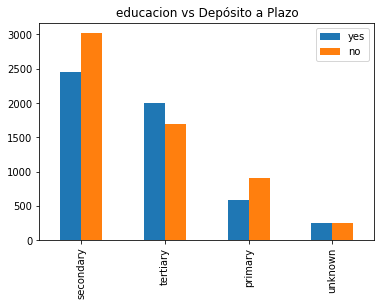

In [13]:
fx_ColumnvsTarget(bank_dp,"educacion","educacion vs Depósito a Plazo")

### Columna: _flag_mora_

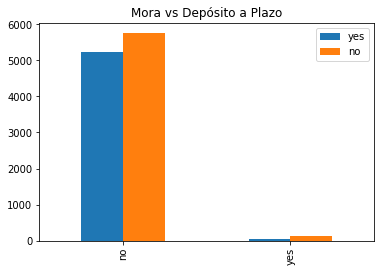

In [14]:
fx_ColumnvsTarget(bank_dp,"flag_mora","Mora vs Depósito a Plazo")

### Columna: _flag_hipotecario_

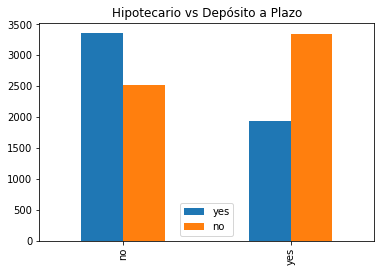

In [15]:
fx_ColumnvsTarget(bank_dp,"flag_hipotecario","Hipotecario vs Depósito a Plazo")

### Columna: _flag_prestamo_

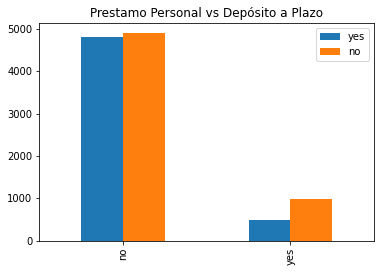

In [16]:
fx_ColumnvsTarget(bank_dp,"flag_prestamo","Prestamo Personal vs Depósito a Plazo")

### Columna: _tipo_contacto_

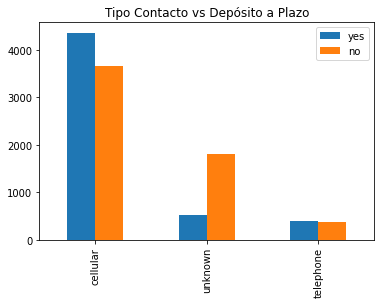

In [17]:
fx_ColumnvsTarget(bank_dp,"tipo_contacto","Tipo Contacto vs Depósito a Plazo")

### Columna: _result_campanha_

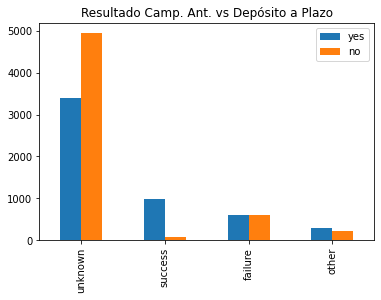

In [18]:
fx_ColumnvsTarget(bank_dp,"result_campanha","Resultado Camp. Ant. vs Depósito a Plazo")

### Columna: _Rango_edad_

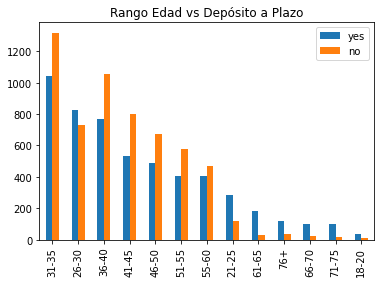

In [19]:
fx_ColumnvsTarget(bank_dp,"Rango_edad","Rango Edad vs Depósito a Plazo")

### Columna: _mes_UltContacto y dia_UltContacto_

Al ser campos que miden el tiempo pueden ser unidos para ver el impacto de ambas variables a la vez, el diagrama de enjambre es una buena representación visual

In [20]:
plt.figure(figsize=(10,5))
sns.swarmplot(x="mes_UltContacto",y="dia_UltContacto",hue="FlagTarget_DP",data=bank_dp,order=("jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"))
plt.show()

TypeError: 'module' object is not callable

**Conclusiones**:
- Los estudiantes y los jubilados tiene un alto interés en el depósito.
- Los clientes con trabajos de "clase obrera" y "servicios" tienen menos probabilidades de suscribirse a un depósito a plazo.
- Los clientes que tienen menos de 30 años y más de 50 años tienen más probabilidades de tomar depósitos a plazo
- El tipo de trabajo como: estudiante, jubilado, desempleado tienden a tomar depósito a plazo.
- Los clientes casados tienen menos probabilidades de suscribirse a un depósito a plazo.
- El cliente que tiene un préstamo hipotecario parece no estar muy interesado en el depósito, y estas han sido las más contactadas en la campaña
- Si el resultado anterior a la campaña es poutcome=success, entonces hay una alta probabilidad de que el cliente muestre interés en el depósito 
- Los clientes con tipo de contacto 'celular' tienen menos probabilidades de suscribirse a un depósito a plazo.
- En el mes de mayo, los registros son altos pero la tasa de interés del cliente es muy inferior
- Los clientes con educación terciaria están tomando depósitos a plazo en comparación con otros.
- Los clientes son más propensos a tomar depósitos a plazo en los meses de enero, febrero, marzo, septiembre, octubre y diciembre
- Las personas que están en trabajos ejecutivos `management` han sido más contactadas por el banco para los depósitos.<br>
- Las personas que están casadas han sido contactadas más por los depósitos por el banco.<br>
- Personas que han sido contactadas más por celular que por teléfono.<br>
- La gente ha sido contactada más en el mes de Julio que en cualquier otro mes. Poco contactados en enero y diciembre.
- El banco se ha puesto en contacto con más personas sin estado en el resultado de la campaña.<br>
- Las personas sin préstamo personal han sido más contactadas por el banco.<br>

## Relación entre características numéricas y target

In [ ]:
#no va tesis
def fx_Column_numericvsTarget(df,name_column_numeric,name_title):
    colum_yes = name_column_numeric+"_YES"
    colum_no = name_column_numeric+"_NO"
    b_df = pd.DataFrame()
    b_df[colum_yes] = (df[df['FlagTarget_DP'] == 'yes'][['FlagTarget_DP',name_column_numeric]].describe())[name_column_numeric]
    b_df[colum_no] = (df[df['FlagTarget_DP'] == 'no'][['FlagTarget_DP',name_column_numeric]].describe())[name_column_numeric]
    print(b_df)
    print(" ")
    b_df.drop(['count', '25%', '50%', '75%']).plot.bar(title = name_title)

In [ ]:
def plotting_kd(data,columns,hue=None):
    if hue==None:    
       plot=sns.FacetGrid(data,size=10).map(sns.distplot,columns)
    else:
        plot=sns.FacetGrid(data,hue=hue,size=10).map(sns.distplot,columns)
        plt.pyplot.legend()

In [ ]:
def violinplot_columns(data,columns,y='FlagTarget_DP'):
    figure(figsize=(15,10))
    sns.violinplot(x=data[y],y=data[columns],hue=data['FlagTarget_DP'],showfliers=False)
    plt.pyplot.title(columns.upper())

### Columna: _prom_saldoAnual_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'prom_saldoAnual',"Estadística de Saldo promedio vs Depósito")

In [ ]:
violinplot_columns(bank_dp,'prom_saldoAnual')

Las personas adquieren más DP si su saldo promedio anual está hasta los `$18 000` aproximadamente y a partir de ahí son outliers, en menor medida para la etiqueta "NO" con `$16 000`aproxy desde ahí outliers.

In [ ]:
plotting_kd(bank_dp,'prom_saldoAnual',hue='FlagTarget_DP')

El saldo promedio anual podría no ser muy útil en la predicción de las etiquetas de clase porque hay mucha superposición.

### Columna: _edad_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'edad',"Estadística de Edad vs Depósito")

In [ ]:
violinplot_columns(bank_dp,'edad')

Gráfico de Violín -Es claramente visible que hay valores atípicos presentes para ambas clases. En la clase No, los valores atípicos están presentes por encima de los 70 años y para la clase Sí, los valores atípicos están presentes por encima de los 75 años. La mediana para la clase No es de alrededor de 40, lo mismo que para la clase Sí. Además, es visible que el rango de IQR casi se superpone, por lo que la edad podría no ser muy útil para predecir el Depósito a Plazo Fijo.

In [ ]:
plotting_kd(bank_dp,'edad',hue='FlagTarget_DP')

Diagrama de distribución -  kdeplot 

Es más claro que la edad podría no ser muy útil en la predicción de las etiquetas de clase porque hay mucha superposición.

### Columna: _dia_UltContacto_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'dia_UltContacto',"Estadística de Día Ult.Contacto vs Depósito")

### Columna: _seg_UltContacto_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'seg_UltContacto',"Estadística de Seg Ult. Contacto vs Depósito")

In [ ]:
violinplot_columns(bank_dp,'seg_UltContacto')

Cualquier duración de la llamada con adquisción a DP como "no", más de 1000 se consideran valores atípicos, mientras los "yes" son más de 1500 se considerarían valores atípicos.

In [ ]:
plotting_kd(bank_dp,'seg_UltContacto',hue='FlagTarget_DP')

Es evidente que la función de duración sería muy útil para predecir las etiquetas de clase. También se menciona en el trabajo de investigación, pero para hacer un modelo predictivo realista, no tenemos que sólo usar esta columna. La mayor parte de la duración de las llamadas con personas que no se han suscrito para los depósitos a largo plazo es entre 0-1000 y con personas que se han suscrito entre 0-2000.

### Columna: _cant_contactoCampanha_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'cant_contactoCampanha',"Estadística de Cant. Contactos vs Depósito")

In [ ]:
violinplot_columns(bank_dp,'cant_contactoCampanha')

Para cualquier etiqueta de clase, las campañas de más de 10 se consideran atípicas.
De la gráfica anterior, hay tantos valores atípicos presentes para la clase "NO" que para la clase "YES". También parece que este gráfico puede no ser muy útil para predecir variables de clase. Grafiquemos en un gráfico de distribución.

In [ ]:
plotting_kd(bank_dp,'cant_contactoCampanha',hue='FlagTarget_DP')

Este gráfico nos dice que la campaña puede no ser muy útil para determinar las etiquetas de clase, ya que hay mucha superposición para ambas clases.

### Columna: _cant_contactoBeforeCampanha_

In [ ]:
fx_Column_numericvsTarget(bank_dp,'cant_contactoBeforeCampanha',"Estadística de Saldo promedio vs Depósito")

In [ ]:
violinplot_columns(bank_dp,'cant_contactoBeforeCampanha')

Las personas que han contactado una vez para la campaña anterior se han suscrito para depósitos a largo plazo. Para la clase "NO", hay tantos valores atípicos que comienzan con el valor 5, pero para la clase "YES", los valores atípicos están presentes desde el valor 9 aproximadamente

In [ ]:
plotting_kd(bank_dp,'cant_contactoBeforeCampanha',hue='FlagTarget_DP')

Existe mucho solapamiento entre clases, por lo tanto no es una buena candita para la predicción de la suscripción al DP.

**Conclusiones**: (check)
- El cliente muestra interés en el depósito que tuvo una llamada de mayor duración `seg_UltContacto` en su último contacto.

## Diagnóstico de correlaciones entre variables y determinación de variables independientes y dependientes

A primera vista, no parece que ninguna de estas variables tenga grados apreciables de correlación. Por lo tanto, a continuación se produce una correlación de mapa de calor con índices:

In [ ]:
bank_dp.FlagTarget_DP = bank_dp.FlagTarget_DP.map({'no':0, 'yes':1}).astype('uint8')

In [ ]:
bank_dp.dtypes

In [ ]:
# Build correlation matrix
corr = bank_dp.corr()
corr.style.background_gradient(cmap='PuBu')

Analizaremos la mayor correlación encontrada:`seg_UltContacto`

**seg_UltContacto**: 
- **Duración de la campaña**: Desde aquí podemos ver que la duración de la llamada de marketing `seg_UltContacto` está moderadamente correlacionada con el depósito (0.451695), significa a que más alta la duración de la llamada es más probable que el cliente aperture un depósisto a plazo.
- **Promedio de la duración de la campaña**: La duración media de la campaña es de 537.32 segundos.
- **Status de la duración de la campaña**: Las personas que estaban por encima del estado de duración tenían más probabilidades de abrir un depósito a plazo. El 77% del grupo que está por encima del promedio en duración abrió depósitos a plazo mientras que los que estaban por debajo del promedio 32% abrió cuentas de depósito a plazo. Esto nos dice que será una buena idea dirigirse a las personas que se encuentran en la categoría superior a la media.

In [ ]:
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_style('whitegrid')
avg_duration = bank_dp['seg_UltContacto'].mean()

lst = [bank_dp]
bank_dp["duration_status"] = np.nan

for col in lst:
    col.loc[col["seg_UltContacto"] < avg_duration, "duration_status"] = "debajo_prom"
    col.loc[col["seg_UltContacto"] > avg_duration, "duration_status"] = "encima_prom"
    
pct_term = pd.crosstab(bank_dp['duration_status'], bank_dp['FlagTarget_DP']).apply(lambda r: round(r/r.sum(), 2) * 100, axis=1)


ax = pct_term.plot(kind='bar', stacked=False, cmap='RdBu')
plt.pyplot.title("Impacto de la duración \n en la apertura de Depósitos a Plazo", fontsize=18)
plt.pyplot.xlabel("Status de duración", fontsize=18);
plt.pyplot.ylabel("Porcentaje (%)", fontsize=18)

for p in ax.patches:
    ax.annotate(str(p.get_height()), (p.get_x() * 1.02, p.get_height() * 1.02))
    

plt.pyplot.show()

In [ ]:
#EXPORT PARQUET
path="../output/"
bank_dp.to_parquet(path+"data-bank_3_EDA.parquet",engine="pyarrow")